<a href="https://colab.research.google.com/github/mahendar8578/SmartSpend-AI/blob/main/SmartSpend_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💰 SmartSpend AI
## AI-Powered Personal Finance Management System

**Objective:**  
Analyze income and expenses, automatically categorize transactions,
identify spending patterns, and provide AI-powered savings recommendations.

**Technology:** Python, Pandas, Matplotlib, Google Colab, Generative AI

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("SmartSpend AI - Project Started Successfully!")

SmartSpend AI - Project Started Successfully!


In [2]:
data = {
    "Date": [
        "2026-11-01",
        "2026-11-02",
        "2026-11-03",
        "2026-11-04",
        "2026-11-05",
        "2026-11-06",
        "2026-11-07",
        "2026-11-08"
    ],

    "Description": [
        "Salary",
        "Swiggy",
        "Petrol",
        "Amazon",
        "College Fee",
        "Movie",
        "Electricity Bill",
        "Grocery"
    ],

    "Amount": [
        30000,
        450,
        1200,
        2000,
        5000,
        300,
        1500,
        2500
    ],

    "Type": [
        "Income",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense",
        "Expense"
    ]
}

df = pd.DataFrame(data)

df

,Date,Description,Amount,Type
0,2026-11-01,Salary,30000,Income
1,2026-11-02,Swiggy,450,Expense
2,2026-11-03,Petrol,1200,Expense
3,2026-11-04,Amazon,2000,Expense
4,2026-11-05,College Fee,5000,Expense
5,2026-11-06,Movie,300,Expense
6,2026-11-07,Electricity Bill,1500,Expense
7,2026-11-08,Grocery,2500,Expense


In [3]:
total_income = df[df["Type"] == "Income"]["Amount"].sum()
total_expenses = df[df["Type"] == "Expense"]["Amount"].sum()
remaining_balance = total_income - total_expenses

print("💰 Total Income: ₹", total_income)
print("💸 Total Expenses: ₹", total_expenses)
print("💵 Remaining Balance: ₹", remaining_balance)

💰 Total Income: ₹ 30000
💸 Total Expenses: ₹ 12950
💵 Remaining Balance: ₹ 17050


In [4]:
# Expense categories
categories = [
    "Food",
    "Transport",
    "Shopping",
    "Education",
    "Entertainment",
    "Bills",
    "Healthcare",
    "Other"
]

# Simple AI-style categorization function
def categorize_transaction(description):
    text = description.lower()

    if any(word in text for word in ["swiggy", "zomato", "restaurant", "food", "hotel"]):
        return "Food"

    elif any(word in text for word in ["petrol", "fuel", "uber", "ola", "bus", "metro"]):
        return "Transport"

    elif any(word in text for word in ["amazon", "flipkart", "shopping", "myntra"]):
        return "Shopping"

    elif any(word in text for word in ["college", "school", "course", "book", "education"]):
        return "Education"

    elif any(word in text for word in ["movie", "netflix", "spotify", "game"]):
        return "Entertainment"

    elif any(word in text for word in ["electricity", "water", "internet", "bill", "recharge"]):
        return "Bills"

    elif any(word in text for word in ["hospital", "medicine", "medical", "pharmacy"]):
        return "Healthcare"

    else:
        return "Other"


# Apply categorization only to expenses
df["Category"] = df.apply(
    lambda row: categorize_transaction(row["Description"])
    if row["Type"] == "Expense"
    else "Income",
    axis=1
)

df

,Date,Description,Amount,Type,Category
0,2026-11-01,Salary,30000,Income,Income
1,2026-11-02,Swiggy,450,Expense,Food
2,2026-11-03,Petrol,1200,Expense,Transport
3,2026-11-04,Amazon,2000,Expense,Shopping
4,2026-11-05,College Fee,5000,Expense,Education
5,2026-11-06,Movie,300,Expense,Entertainment
6,2026-11-07,Electricity Bill,1500,Expense,Bills
7,2026-11-08,Grocery,2500,Expense,Other


In [5]:
expense_data = df[df["Type"] == "Expense"]

category_spending = (
    expense_data
    .groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Spending by Category:")
print(category_spending)

Spending by Category:
Category
Education        5000
Other            2500
Shopping         2000
Bills            1500
Transport        1200
Food              450
Entertainment     300
Name: Amount, dtype: int64


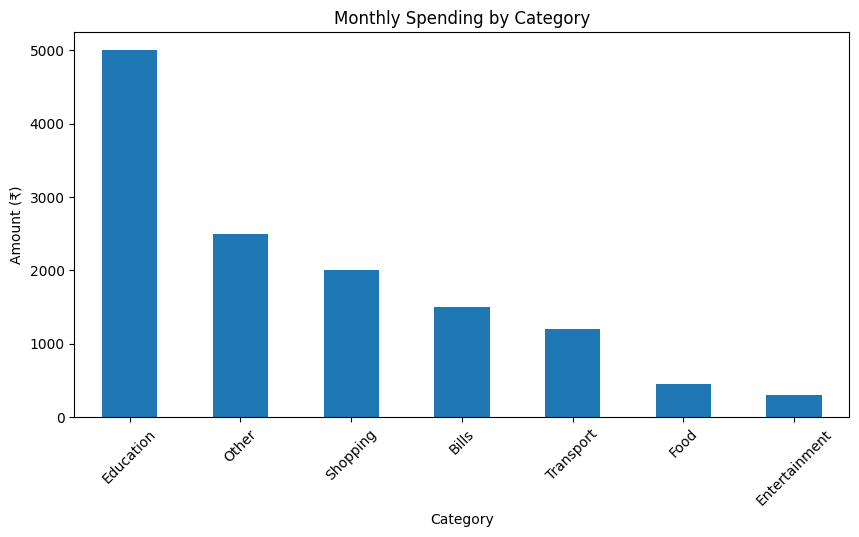

In [6]:
plt.figure(figsize=(10, 5))

category_spending.plot(kind="bar")

plt.title("Monthly Spending by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)

plt.show()

In [9]:
!pip install -q "google-genai>=2.12.1,<3"

In [10]:
from google.colab import userdata
from google import genai

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini AI connected successfully!")

Gemini AI connected successfully!


In [17]:
import time

def get_ai_recommendation(prompt, max_retries=4):
    for attempt in range(max_retries):
        try:
            response = client.models.generate_content(
                model="gemini-3.8-flash",
                contents=prompt
            )
            return response.text

        except Exception as e:
            if "503" in str(e):
                wait_time = 5 * (attempt + 1)
                print(f"AI service busy. Retrying in {wait_time} seconds...")
                time.sleep(wait_time)
            else:
                raise e

    return "AI service is temporarily unavailable. Please try again later."


ai_result = get_ai_recommendation(prompt)

print(ai_result)

AI service busy. Retrying in 5 seconds...
Here is a simple analysis of your monthly finances:

### 1. Spending Analysis
You are in a very strong financial position. You are spending only about **43% of your income** (₹12,950) and saving nearly **57%** (₹17,050), which is well above average. However, non-essential and untracked spending—specifically "Other" (₹2,500) and "Shopping" (₹2,000)—makes up about a third of your total expenses, meaning there is still room to optimize.

---

### 2. Highest Spending Category
* **Education:** **₹5,000** (This accounts for approximately 38.6% of your total monthly expenses). Since this is an investment in your personal or professional growth, it is generally considered a productive expense.

---

### 3. Two Practical Ways to Improve Savings
1. **Track the "Other" category:** At ₹2,500, "Other" is your second-largest expense. Break this down for a month to see where the money is going; small, untracked daily expenses often add up quickly.
2. **Apply 